# Scale-Free Networks

Code examples from [Think Complexity, 2nd edition](https://thinkcomplex.com).

Copyright 2016 Allen Downey, [MIT License](http://opensource.org/licenses/MIT)

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import seaborn as sns

from utils import decorate, savefig

# I set the random seed so the notebook 
# produces the same results every time.
np.random.seed(17)

# TODO: remove this when NetworkX is fixed
# from warnings import simplefilter
# import matplotlib.cbook
# simplefilter("ignore", matplotlib.cbook.mplDeprecation)

## Exercises

**Exercise:** Data files from the Barabasi and Albert paper are available from
[this web page](http://www3.nd.edu/~networks/resources.htm).

Their actor collaboration data is included in the repository for this book in a file named
`actor.dat.gz`.  The following function reads the file and builds the graph.

Клика — это группа узлов, в которой каждый связан с каждым другим. Все со всеми знакомы, нет ни одной пары без связи.

Пример. Фильм с 4 актёрами A, B, C, D. Код all_pairs соединяет всех попарно, получаются 6 связей:

A–B  A–C  A–D
B–C  B–D
C–D

Это клика из 4 узлов. Формула числа связей: k(k-1)/2. Для k=4 это 4·3/2 = 6.

In [2]:
import gzip

def read_actor_network(filename, n=None):
    """Reads graph data from a file.
    
    filename: string
    n: int, number of lines to read (default is all)
    """
    G = nx.Graph()
    with gzip.open(filename) as f:
        for i, line in enumerate(f):
            nodes = [int(x) for x in line.split()]
            G.add_edges_from(all_pairs(nodes))
            if n and i >= n:
                break
    return G

def all_pairs(nodes):
    """Generates all pairs of nodes."""
    for i, u in enumerate(nodes):
        for j, v in enumerate(nodes):
            if i < j:
                yield u, v

Compute the number of actors in the graph and the number of edges.

Check whether this graph has the small world properties, high clustering and low
path length.

Plot the PMF of degree on a log-log scale.  Does it seem to follow a power law?

Also plot the CDF of degree on a log-x scale, to 
see the general shape of the distribution, and on a log-log scale, to see whether 
the tail follows a power law.

Note: The actor network is not connected, so you might want to use
`nx.connected_components` to find connected subsets of the
nodes.

In [3]:
# WARNING: if you run this with larger values of `n`, you
# might run out of memory, and Jupyter does not handle that well.

%time actors = read_actor_network('data/actor.dat.gz', n=10000)
len(actors)

CPU times: user 385 ms, sys: 24.5 ms, total: 409 ms
Wall time: 414 ms


17540

In [4]:
# Solution goes here
print(f'актеров: {actors.number_of_nodes()}')
print(f'связей: {actors.number_of_edges()}')
print(f'средняя степень {2 * actors.number_of_edges() / actors.number_of_nodes()}')

актеров: 17540
связей: 336377
средняя степень 38.35541619156214


In [5]:
# Solution goes here
components = list(nx.connected_components(actors))
print(f'связанные подграфы: {len(components)}')

biggest = max(components, key=len)
print(f'наибольший подграф: {len(biggest)}')

core = actors.subgraph(biggest).copy()

связанные подграфы: 55
наибольший подграф: 17270


In [6]:
# Solution goes here
C = nx.average_clustering(core)
print(f'средняя кластеризация {C=}')

средняя кластеризация C=0.730661579602017


примерно в 73% случаев два партнёра одного актёра тоже снимались вместе

In [7]:
# Solution goes here
import random

random.seed(42)
starts = random.sample(list(core.nodes()), 1000)

lengths = []
for s in starts:
    dist = nx.single_source_shortest_path_length(core, s)
    lengths.extend(dist.values())

L = sum(lengths) / len(lengths)
print(f'средняя длина пути {L=}')
print(f'максимальная в выборке {max(lengths)}')

средняя длина пути L=3.528326462072959
максимальная в выборке 10


In [8]:
# Solution goes here
n = core.number_of_nodes()
k = 2 * core.number_of_edges() / n   # средняя степень core
p = k / (n - 1)                      # вероятность ребра, чтобы степень совпала

rand = nx.fast_gnp_random_graph(n, p, seed=17)
print(f'{p=:.5f}, рёбер {rand.number_of_edges()}')

C_rand = nx.average_clustering(rand)
print(f'кластеризация случайного {C_rand=}')

starts = random.sample(list(rand.nodes()), 200)
lengths = []
for s in starts:
    lengths.extend(nx.single_source_shortest_path_length(rand, s).values())
L_rand = sum(lengths) / len(lengths)
print(f'длина пути случайного {L_rand=}')

p=0.00225, рёбер 335484
кластеризация случайного C_rand=0.0022596817575671257
длина пути случайного L_rand=2.9540243196294154


в случайном графе средняя кластеризация (вероятность связи между двумя партнёрами одного и того же актёра) равна вероятности появления ребра

| | актёры | случайный |
|---|---|---|
| C | 0,73 | 0,0023 (≈ p) |
| L | 3,55 | 2,95 |

Saving figure to file figs/chap04-1


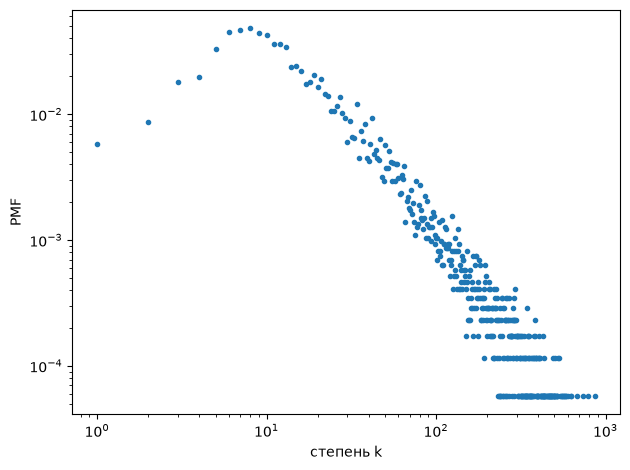

In [10]:
# Solution goes here
degrees = [d for _, d in core.degree()]

ks, counts = np.unique(degrees, return_counts=True)
pmf = counts / len(degrees)

plt.loglog(ks, pmf, 'o', markersize=3)
decorate(xlabel='степень k', ylabel='PMF')
savefig('figs/chap04-1')

PMF (функция вероятности) показывает, какая доля актёров имеет степень ровно k. Например, сколько процентов актёров имеют ровно 10 партнёров, сколько ровно 100.

На log-log графике PMF средняя часть (k от 10 до 200) примерно ложится на прямую, что указывает на степенной закон. Слева есть горб около k ≈ 8: в нашей выборке мало актёров с очень малой степенью. Справа точки образуют горизонтальные полки из-за малых чисел (1, 2, 3 актёра на значение), поэтому по PMF хвост судить нельзя. Распределение сильно скошено: средняя степень 38, а максимальная почти 1000, в отличие от случайного графа, где степени группируются у среднего.

Saving figure to file figs/chap04-2


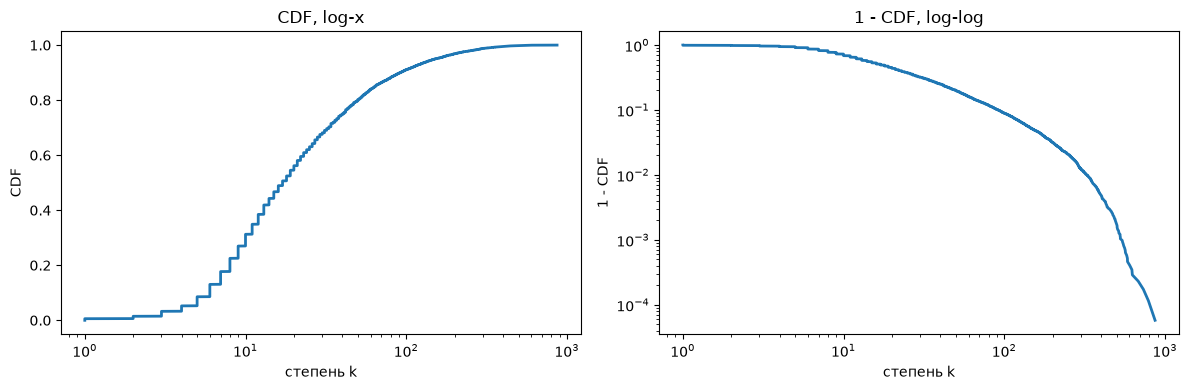

In [11]:
# Solution goes here
xs = np.sort(degrees)
n = len(xs)
cdf = np.arange(1, n + 1) / n        # доля со степенью <= x
ccdf = 1 - np.arange(n) / n          # доля со степенью >= x

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.semilogx(xs, cdf)
ax1.set(xlabel='степень k', ylabel='CDF', title='CDF, log-x')

ax2.loglog(xs, ccdf)
ax2.set(xlabel='степень k', ylabel='1 - CDF', title='1 - CDF, log-log')

plt.tight_layout()
savefig('figs/chap04-2')

слева доля актёров со степенью не больше k, справа - не меньше

- Ступеньки слева — реальные значения степени 1, 2, 3… (их немного, поэтому видны отдельные шаги).
- CDF достигает 0,5 примерно при k ≈ 15: у половины актёров не больше ~15 партнёров.
- 0,9 достигается около k ≈ 100: у 90% актёров не больше сотни.
- Но ось тянется до ~900. Оставшиеся 10% актёров растянуты на огромный диапазон. Значит, распределение сильно скошено: большинство сосредоточено внизу, а «звёзды» уходят далеко вправо.

Сеть актёров обладает свойствами «тесного мира»: кластеризация (0,73) в 300 раз выше, чем у случайного графа, а длина пути (3,55) почти такая же. Распределение степеней сильно скошено: у половины актёров не больше ~15 партнёров, а максимум почти 1000. На log-log графиках середина распределения примерно прямая, что похоже на степенной закон, но хвост загибается вниз, поэтому закон не чистый, а с обрезанием.

**Exercise:** NetworkX provides a function called `powerlaw_cluster_graph` that implements the "Holme and Kim algorithm for growing graphs with powerlaw degree distribution and approximate average clustering".  Read the documentation of this function and see if you can use it to generate a graph that has the same number of nodes as the Facebook network, the same average degree, and the same clustering coefficient.  How does the degree distribution in the model compare to the actual distribution?

In [12]:
# Solution goes here
fb = nx.read_edgelist('data/facebook_combined.txt.gz', nodetype=int)

n = fb.number_of_nodes()
k = 2 * fb.number_of_edges() / n
C = nx.average_clustering(fb)
print(f'{n=}, рёбер {fb.number_of_edges()}, {k=:.2f}, {C=:.3f}')

n=4039, рёбер 88234, k=43.69, C=0.606


Как работает модель. Сеть растёт по узлу: новый узел приходит и сразу создаёт m связей. Это единственный способ, которым в модели появляются связи. Узлов n, значит, связей получается примерно n · m.

Подставляем в формулу средней степени:

средняя степень = 2 · связи / узлы = 2 · (n · m) / n = 2m

n сокращается, остаётся 2m.

Отсюда m:

2m = k  →  m = k/2  →  округляем до целого

In [13]:
# Solution goes here
m = round(k / 2)
print(f'{m=}')

for p in [0, 0.25, 0.5, 0.75, 1]:
    model = nx.powerlaw_cluster_graph(n, m, p, seed=42)
    k_model = 2 * model.number_of_edges() / model.number_of_nodes()
    C_model = nx.average_clustering(model)
    print(f'{p=}: k={k_model:.2f}, C={C_model:.3f}')

m=22
p=0: k=43.76, C=0.038
p=0.25: k=43.59, C=0.085
p=0.5: k=43.54, C=0.104
p=0.75: k=43.62, C=0.097
p=1: k=43.75, C=0.284


Подобрать m = 22 и p = 1 удалось, чтобы число узлов и средняя степень совпали с Facebook. Кластеризация не совпала ни при каком p: максимум 0,28 против 0,606. Модель не создаёт плотных групп, где все знакомы между собой.

In [14]:
# Solution goes here
model = nx.powerlaw_cluster_graph(n, m, 1, seed=42)

Saving figure to file figs/chap04-3


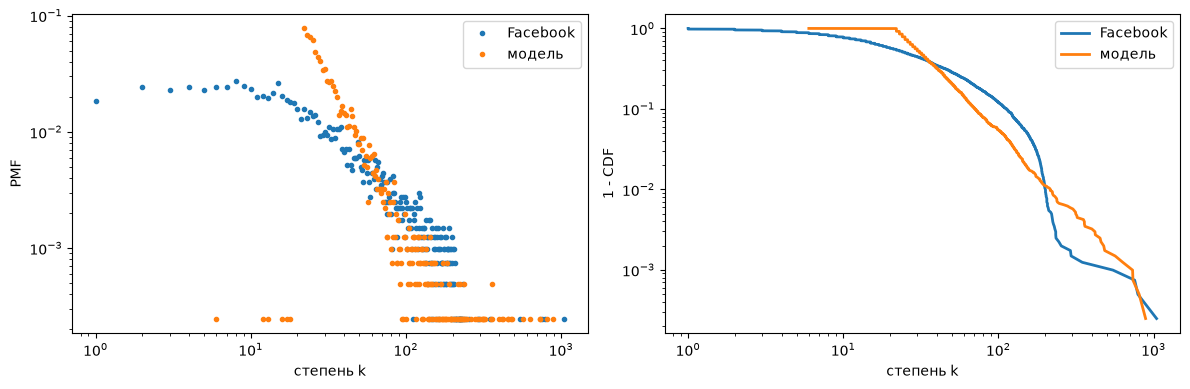

In [15]:
# Solution goes here
def degree_pmf(g):
    degs = [d for _, d in g.degree()]
    ks, counts = np.unique(degs, return_counts=True)
    return ks, counts / len(degs)

def degree_ccdf(g):
    xs = np.sort([d for _, d in g.degree()])
    return xs, 1 - np.arange(len(xs)) / len(xs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for name, g in [('Facebook', fb), ('модель', model)]:
    ks, pmf = degree_pmf(g)
    ax1.loglog(ks, pmf, 'o', markersize=3, label=name)
    xs, ccdf = degree_ccdf(g)
    ax2.loglog(xs, ccdf, label=name)

ax1.set(xlabel='степень k', ylabel='PMF')
ax2.set(xlabel='степень k', ylabel='1 - CDF')
ax1.legend()
ax2.legend()
plt.tight_layout()
savefig('figs/chap04-3')

Что совпадает.
- Хвост. Обе сети тянутся до степени около 1000, у обеих есть «звёзды» в сотни связей. На правом графике линии в области 100–1000 идут рядом и заканчиваются в одной точке.
- Общая форма. Обе падают вниз по степенному типу: много «обычных» узлов и мало гигантов.

Что отличается.
- Малые степени. У Facebook много людей с малым числом друзей: степени от 1 до 20 дают заметную долю (левый график, синие точки слева, ровная «полка» около 2·10⁻²). У модели таких почти нет: оранжевые точки начинаются около k ≈ 22, и их значения резко взлетают к 7·10⁻² (оранжевый пик на левом графике). Причина в самой модели: каждый новичок приносит ровно m = 22 связи, поэтому степень меньше 22 почти ни у кого не бывает.
- Середина. В модели доля узлов со степенью 22–50 больше, чем у Facebook, потому что там люди собраны в узкую полосу у m. У Facebook распределение шире.
- Форма хвоста. У Facebook на правом графике есть «ступенька» около 200 и более резкий обрыв, у модели линия плавнее.

Модель воспроизводит общую форму: тяжёлый хвост со «звёздами» до ~1000 связей, как у Facebook. Но она не создаёт узлов со степенью меньше m = 22, поэтому у неё нет левой части распределения, которая есть у Facebook, и степени сосредоточены в узкой области около m. Кроме того, как мы выяснили ранее, кластеризация не совпадает (0,28 против 0,606).

In [16]:
# Solution goes here

In [17]:
# Solution goes here

In [18]:
# Solution goes here

In [19]:
# Solution goes here